In [1]:
%pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: C:\Users\Hp\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [2]:
import keras
from keras.models import Sequential
from keras.layers import Conv2D, MaxPooling2D,Dense, Flatten
from keras.utils import to_categorical
from keras.datasets import mnist
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [3]:
(xtrain,ytrain),(xtest,ytest)=mnist.load_data()

In [4]:
xtrain=xtrain.reshape((xtrain.shape[0],28,28,1))
xtest=xtest.reshape((xtest.shape[0],28,28,1))

In [5]:
train_norm = xtrain.astype('float32')
test_norm = xtest.astype('float32')
xtrain = train_norm/255.0
xtest = test_norm/255.0

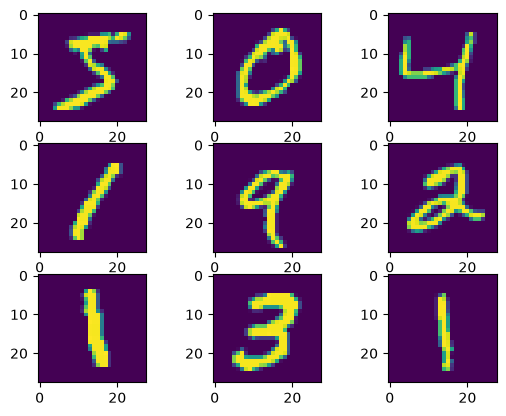

In [6]:
for i in range(9):
  plt.subplot(330+1+i)
  plt.imshow(xtrain[i])

In [7]:
model = Sequential()
model.add(Conv2D(32,(3,3),activation='relu',input_shape=(28,28,1)))
model.add(MaxPooling2D(2,2))
model.add(Flatten())
model.add(Dense(100,activation='relu'))
model.add(Dense(10,activation='softmax'))

C:\Users\Hp\AppData\Roaming\Python\Python314\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [8]:
model.compile(optimizer='sgd',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

In [9]:
history=model.fit(xtrain,ytrain,epochs=20,validation_data=(xtest,ytest))

Epoch 1/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 18s 9ms/step - accuracy: 0.8681 - loss: 0.4804 - val_accuracy: 0.9278 - val_loss: 0.2483
Epoch 2/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9344 - loss: 0.2232 - val_accuracy: 0.9466 - val_loss: 0.1767
Epoch 3/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9501 - loss: 0.1694 - val_accuracy: 0.9533 - val_loss: 0.1582
Epoch 4/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9589 - loss: 0.1384 - val_accuracy: 0.9641 - val_loss: 0.1195
Epoch 5/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.9646 - loss: 0.1181 - val_accuracy: 0.9657 - val_loss: 0.1160
Epoch 6/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - accuracy: 0.9687 - loss: 0.1035 - val_accuracy: 0.9694 - val_loss: 0.0950
Epoch 7/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - accuracy: 0.9718 - loss: 0.0917 - val_accuracy: 0.9708 - val_loss: 0.0921
Epoch 8/20
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.9756 - loss: 0

In [10]:
predictions =model.predict(xtest)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step  


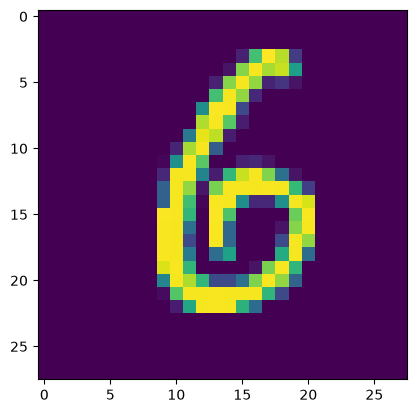

In [11]:
import random
index = random.randint(1,10000)
plt.imshow(xtest[index])

In [12]:
pred_num = max(predictions[index])
for i in range(len(predictions[index])):
    if(predictions[index][i] == pred_num):
        print("Predicted number is: ",i)
        break
     

Predicted number is:  6


In [13]:
print(model.evaluate(xtest,ytest))
     

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9813 - loss: 0.0573  
[0.05726602301001549, 0.9812999963760376]


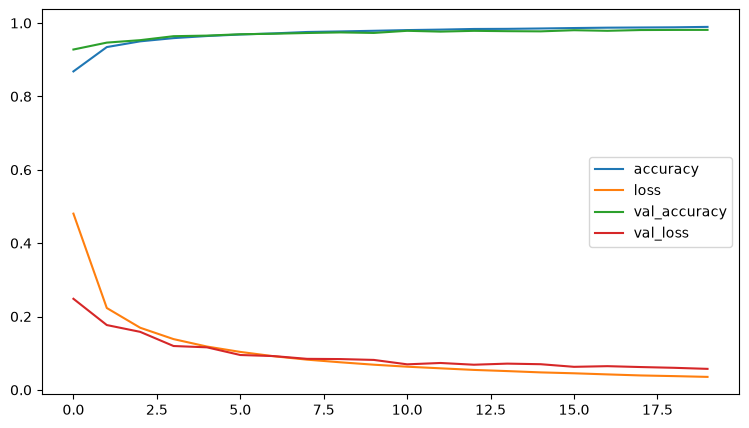

In [14]:
import pandas as pd
pd.DataFrame(history.history).plot(figsize=(9,5))
plt.show()

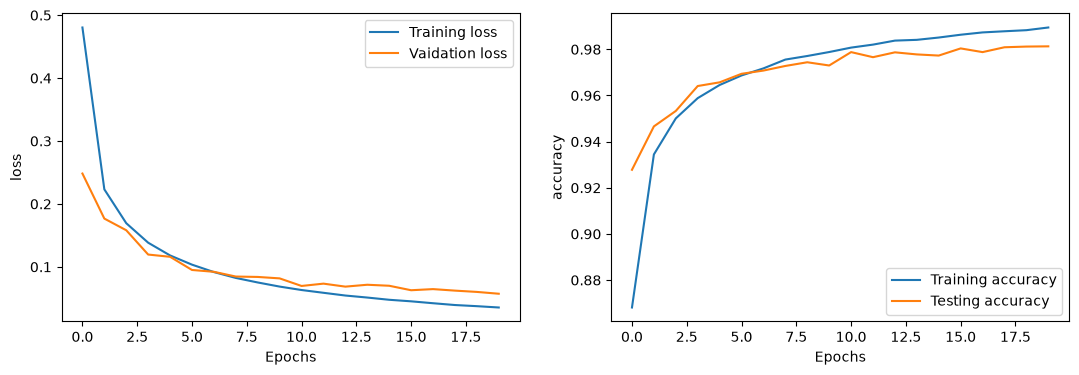

In [15]:
plt.figure(figsize=(13,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'],label='Training loss')
plt.plot(history.history['val_loss'],label='Vaidation loss')
plt.xlabel('Epochs')
plt.ylabel('loss')
plt.legend()
plt.subplot(1,2,2)
plt.plot(history.history['accuracy'],label='Training accuracy')
plt.plot(history.history['val_accuracy'],label='Testing accuracy')
plt.xlabel('Epochs')
plt.ylabel('accuracy')
plt.legend()

In [ ]:
Problem Statement:
Implementing Feed forward Neural Network with Keras and Tensorflow.
1. Import the necessary packages
2. Load the training and testing data(MNIST)
3. Define the network architecture using keras
4. Train the model using SGD
5. Evaluate the network
6. Plot the training loss and accuracy

Objectives:
1. Understand how to use Tensorflow Eager and Keras Layers to build a neural network architecture.
2. Understand how a model is trained and evaluated.
3. Identify digits from images.
4. Our main goal is to train a neural network (using Keras) to obtain > 90% accuracy on MNIST dataset.
5. Research at least 1 technique that can be used to improve model generalization.

Solution Expected:
Implement and train a feed-forward neural network (also known as an "MLP" for "multi-layer perceptron") on a dataset called MNIST and improve model 
generalization by achieving increased accuracy and decrease loss where model gains good confidence with the prediction.

Methodology to be used
⮚ Deep Learning
⮚ Feed Forward Neural Network

Theory:
Deep learning has revolutionized the world of machine learning as more and more ML practitioners haveadopted deep learning networks to solve real-world
problems. Compared to the more traditional ML models, deep learning networks have been shown superior performance for many applications. The first step 
toward using deep learning networks is to understand the working of a simple feedforward neural network we get started with how we can build our first
neural network model using Keras running on top of the Tensorflow library.TensorFlow is an open-source platform for machine learning. Keras is the 
high-level application programming interface (API) of TensorFlow. Using Keras, we can rapidly develop a prototype system and test it out. This is the 
first in a three-part series on using TensorFlow for supervised classification tasks. A Conceptual Diagram of the Neural Network:
we’ll build a supervised classification model that learns to identify digits from images. We’ll use the well- known MNIST dataset to train and test our
model. The MNIST dataset consists of 28-by-28 images of handwritten digits along with their corresponding labels.
We’ll construct a neural network with one hidden layer to classify each digit image into its corresponding label. The figure below shows a conceptual 
diagram of the neural network we are about to build. The output layer consists of 10 units, where each unit corresponds to a different digit. Each unit 
computes a value that can be interpreted as the confidence value of its respective digit. The final classification is the digit with the maximum 
confidence value.

TensorFlow and Keras Libraries:
If Keras and TensorFlow are not installed on your system, you can easily do so using pip or conda depending upon your Python environment.
pip install tensorflow
In the context of ML, a tensor is a multidimensional array, which in its simplest form is a scalar. Vectors and matrices are special cases of tensors.
In TensorFlow, a tensor is a data structure. It is a multidimensional array composed of elements of the same type. Tensors are used to encapsulate 
all inputs and outputs to a deep learning network. The training dataset and each test example has to be cast as a tensor. All operations within the 
layers of the network are also performed on tensors.
    
Layers in TensorFlow:
You can build a fully connected feedforward neural network by stacking layers sequentially so that the output of one layer becomes the input to the next.
In TensorFlow, layers are callable objects, which take tensors as input and generate outputs that are also tensors. Layers can contain weights and biases
, which are both tuned during the training phase. We’ll create a simple neural network from two layers:
1. Flatten layer
2. Dense layer
    
The Flatten Layer:
This layer flattens an input tensor without changing its values. Given a tensor of rank n, the Flatten layer reshapes it to a tensor of rank 2. The number of elements on the first axis remains unchanged. The elements of the input tensor’s remaining axes are stacked together to form a single axis. We need this layer to create a vectorized version of each image for further input to the next layer.
The Dense Layer
The dense layer is the fully connected, feedforward layer of a neural network. It computes the weighted sum of the inputs, adds a bias, and passes the output through an activation function. We are using the ReLU activation function for this example. This function does not change any value greater than 0. The rest of the values are all set to 0.
The computations of this layer for the parameters shown in the code above are all illustrated in the figure below.
21
he Neural Network:
model = tf.keras.Sequential([ tf.keras.layers.Flatten(input_shape=(28, 28)), tf.keras.layers.Dense(64, activation='relu'), tf.keras.layers.Dense(10, activation='softmax')
])
Figure 2: Hidden layer computations.
Creating a Model in TensorFlow:
We are now ready to create a model of a simple neural network with one hidden layer. The simplest method is to use Sequential() with a list of all the layers you want to stack together. The code below creates a model and prints its summary. Note the use of relu as the activation function in the first dense layer and a softmax in the output layer. The softmax function normalizes all outputs to sum to 1 and ensures that they are in the range [0, 1].
Compile the Model
Next we compile the model. Here, we specify the optimizer and loss function of our model. The optimization algorithm determines how the connection weights are updated at each training step with respect to the given loss function. Because we have a multiclass classification problem, the loss function we’ll use is categorical_crossentropy, coupled with the adam optimizer. You can experiment with other optimizers too. The value of the metrics argument sets the parameter to monitor and record during the training phase.
Train t
Now that the model is ready, it’s time to train it. We’ll load the dataset, train the model, and view the training process. Note that the outputs shown here will vary with every run of the program because of the
model.compile(optimizer='sgd', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
22
stochastic nature of the algorithms involved.
Load the Dataset:
The following code loads the training set and the test set of the MNIST data. It also prints the statistics of both sets. Because our model has 10 outputs, one for each digit, we need to convert the absolute image labels to categorical ones. The utils module in the Keras library provides the method to_categorical() for this conversion.
Train the Model:
The fit() method of the model object trains the neural network. If you want to use a validation set during training, all you have to do is define the percentage of validation examples to be taken from the training set. The splitting of the training set into a train and validation set is automatically taken care of by the fit() method.
In the code below, the fit() method is called in 10 epochs.
View the Training Process:
The fit() method returns a history object with detailed information regarding model training. The history attribute is a dictionary object.
To view the learning process, we can plot the accuracy and loss corresponding to different epochs for both the training and validation sets. The following code creates two graphs for these two metrics.
The predict() method:
If you want to see the output of the network for one or more train/test examples, use the predict() method. The following example code prints the values of the output layer when the first test image is used as an input. It is a 10-dimensional vector of confidence values corresponding to each digit. The final classification of the image is the argmax() of this vector.
The evaluate() method:
The evaluate() method computes the overall accuracy of the model on the dataset passed as an argument. The code snippet below prints the classification accuracy on both the training set and the test set.